# Lab03 — Figuras obligatorias
**Isabela Torres-Septien Uribe · Andrea Santoyo Vega · Abdon Islas León**

Todas las figuras leen de `artifacts/`. Corre de arriba hacia abajo.

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

REPO_ROOT = os.path.abspath(".")   # ajusta si el notebook NO esta en la raiz del repo
os.chdir(REPO_ROOT); sys.path.insert(0, REPO_ROOT)
plt.rcParams["figure.figsize"] = (11, 4)
ART = "artifacts"
chosen = json.load(open(f"{ART}/chosen_group.json"))
cols = chosen["grupo"].split("+")
print("Repo:", REPO_ROOT, "| grupo:", chosen["grupo"])

Repo: c:\Users\Isabela\Documents\Iteso\9no Semestre\Trading\Lab03_MyST_Isabela-Andrea-Abdon-repository | grupo: AMT+SBAC


### Figura 1 — Precios individuales del grupo
Precio de cada activo del grupo por separado; muestra que ambos comparten la misma tendencia de fondo.

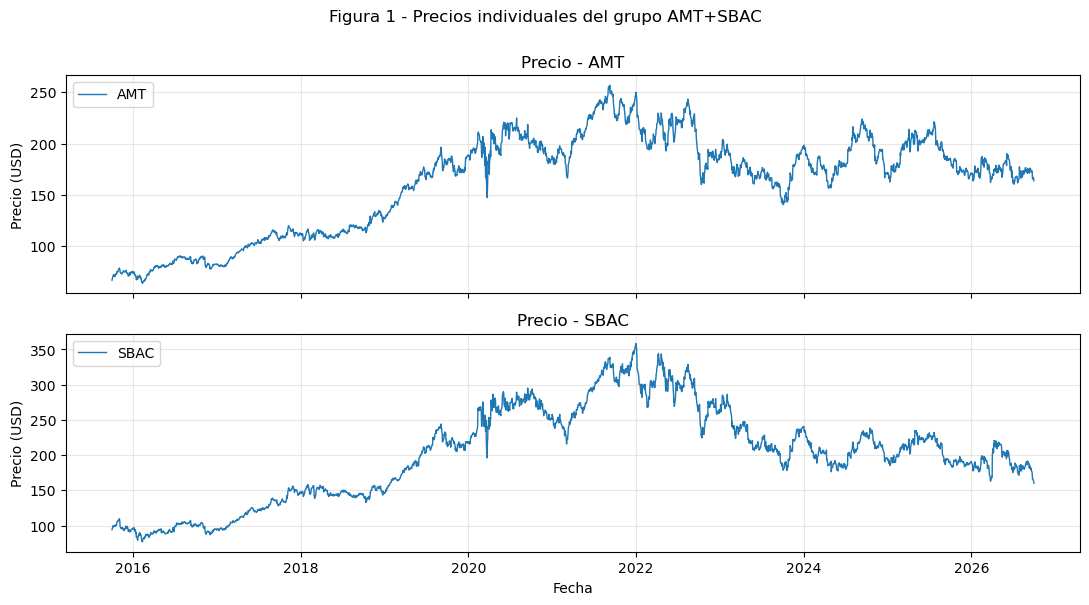

In [2]:
full = pd.read_csv(f"{ART}/prices_full.csv", index_col=0, parse_dates=True)[cols]
fig, axes = plt.subplots(len(cols), 1, figsize=(11, 3*len(cols)), sharex=True)
axes = np.atleast_1d(axes)
for ax, cc in zip(axes, cols):
    ax.plot(full.index, full[cc], lw=1, color="#1f77b4", label=cc)
    ax.set_title(f"Precio - {cc}"); ax.set_ylabel("Precio (USD)")
    ax.legend(loc="upper left"); ax.grid(alpha=0.3)
axes[-1].set_xlabel("Fecha")
fig.suptitle(f"Figura 1 - Precios individuales del grupo {chosen['grupo']}", y=1.001)
plt.tight_layout(); plt.show()

### Figura 2 — Spread con señales
El spread del portafolio con las entradas (largo/corto) y salidas marcadas; muestra cómo la estrategia opera las desviaciones del equilibrio.

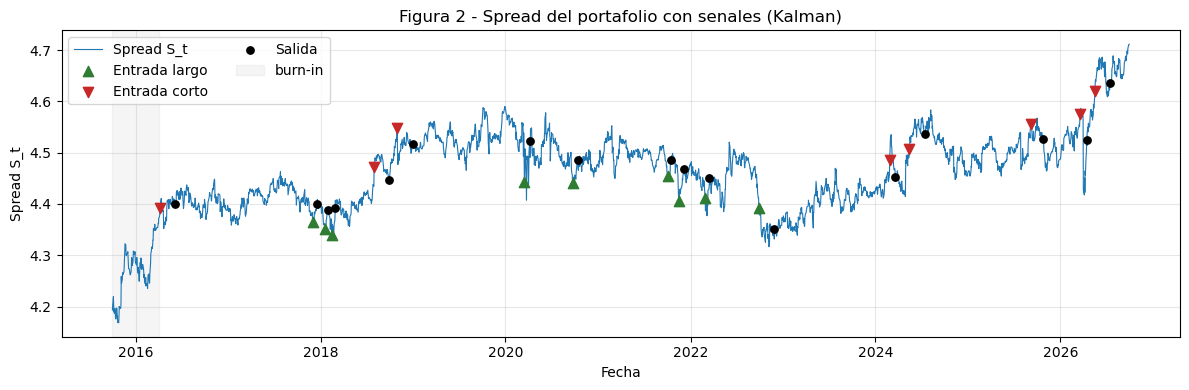

In [3]:
s = pd.read_csv(f"{ART}/senales_kalman.csv", index_col=0, parse_dates=True)
spread = s["s"]; d = s["d"].fillna(0).astype(int); dprev = d.shift(1).fillna(0).astype(int)
ent_long  = s.index[(d == 1)  & (dprev != 1)]
ent_short = s.index[(d == -1) & (dprev != -1)]
salidas   = s.index[(d == 0)  & (dprev != 0)]
burn = s["en_burn_in"].astype(str).str.strip().str.lower().isin(["true", "1"])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spread.index, spread.values, lw=0.8, color="#1f77b4", label="Spread S_t")
ax.scatter(ent_long,  spread.loc[ent_long],  marker="^", s=55, color="#2e7d32", label="Entrada largo", zorder=3)
ax.scatter(ent_short, spread.loc[ent_short], marker="v", s=55, color="#c62828", label="Entrada corto", zorder=3)
ax.scatter(salidas,   spread.loc[salidas],   marker="o", s=28, color="black",   label="Salida", zorder=3)
if burn.any(): ax.axvspan(s.index[0], s.index[burn].max(), color="gray", alpha=0.08, label="burn-in")
ax.set_title("Figura 2 - Spread del portafolio con senales (Kalman)")
ax.set_xlabel("Fecha"); ax.set_ylabel("Spread S_t"); ax.legend(loc="upper left", ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Figura 3 — Vector de pesos β̂_t (Kalman filtro 1)
El hedge ratio estimado por el filtro de Kalman 1 en el tiempo; muestra cómo se adapta en vez de quedar fijo.

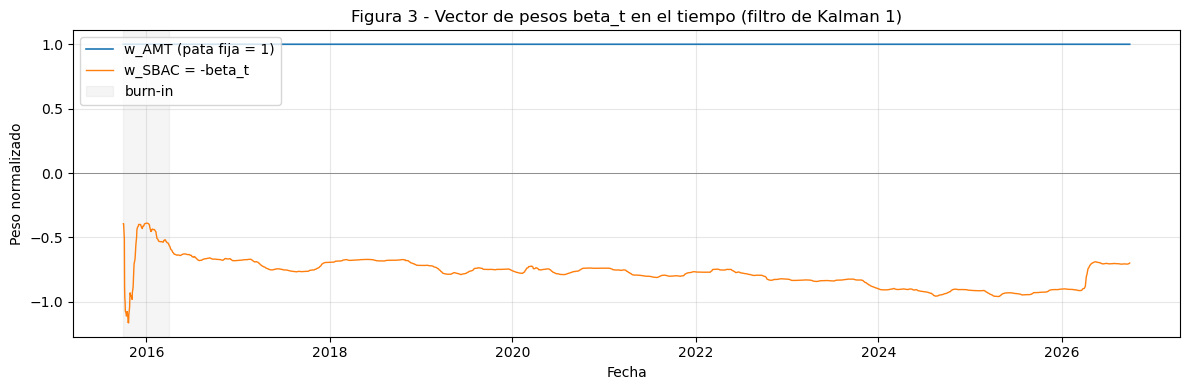

In [4]:
s = pd.read_csv(f"{ART}/senales_kalman.csv", index_col=0, parse_dates=True)
burn = s["en_burn_in"].astype(str).str.strip().str.lower().isin(["true", "1"])
pesos = pd.DataFrame({"w_"+cols[0]: 1.0, "w_"+cols[1]: -s["beta"]}, index=s.index)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pesos.index, pesos["w_"+cols[0]], lw=1.2, color="#1f77b4", label=f"w_{cols[0]} (pata fija = 1)")
ax.plot(pesos.index, pesos["w_"+cols[1]], lw=1.0, color="#ff7f0e", label=f"w_{cols[1]} = -beta_t")
ax.axhline(0, color="gray", lw=0.6)
if burn.any(): ax.axvspan(s.index[0], s.index[burn].max(), color="gray", alpha=0.08, label="burn-in")
ax.set_title("Figura 3 - Vector de pesos beta_t en el tiempo (filtro de Kalman 1)")
ax.set_xlabel("Fecha"); ax.set_ylabel("Peso normalizado"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Figura 4 — Primer eigenvector de Johansen (ventana móvil)
El eigenvector de cointegración reestimado en ventanas de 252 días; indica si la relación es estable o se mueve.

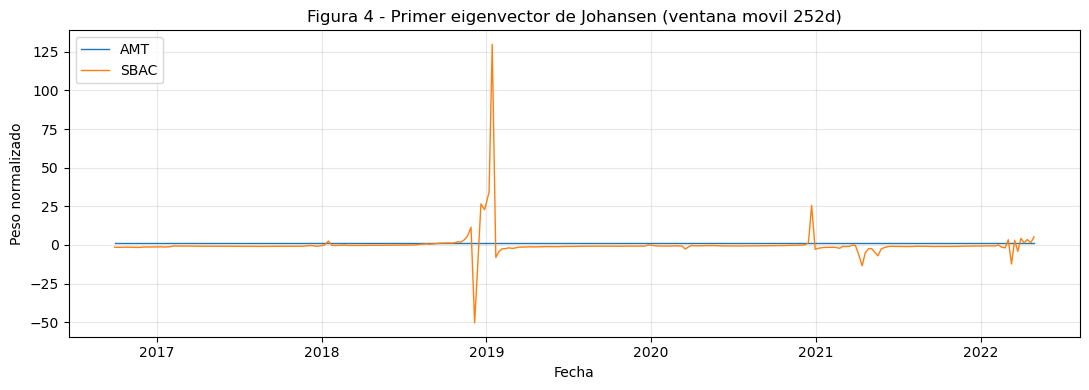

In [5]:
roll = pd.read_csv(f"{ART}/rolling_eigenvector.csv", index_col=0, parse_dates=True)
fig, ax = plt.subplots()
for cc in roll.columns: ax.plot(roll.index, roll[cc], lw=1, label=cc)
ax.set_title("Figura 4 - Primer eigenvector de Johansen (ventana movil 252d)")
ax.set_xlabel("Fecha"); ax.set_ylabel("Peso normalizado"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Figura 5 — Ganancia de Kalman de ambos filtros
El filtro 1 (pesos) tiene ganancia que decae al aprender; el filtro 2 (señal) mantiene ganancia constante (1/L) por diseño.

check beta (f1): 3.75e-01  |  check z (f2): 5.44e-14


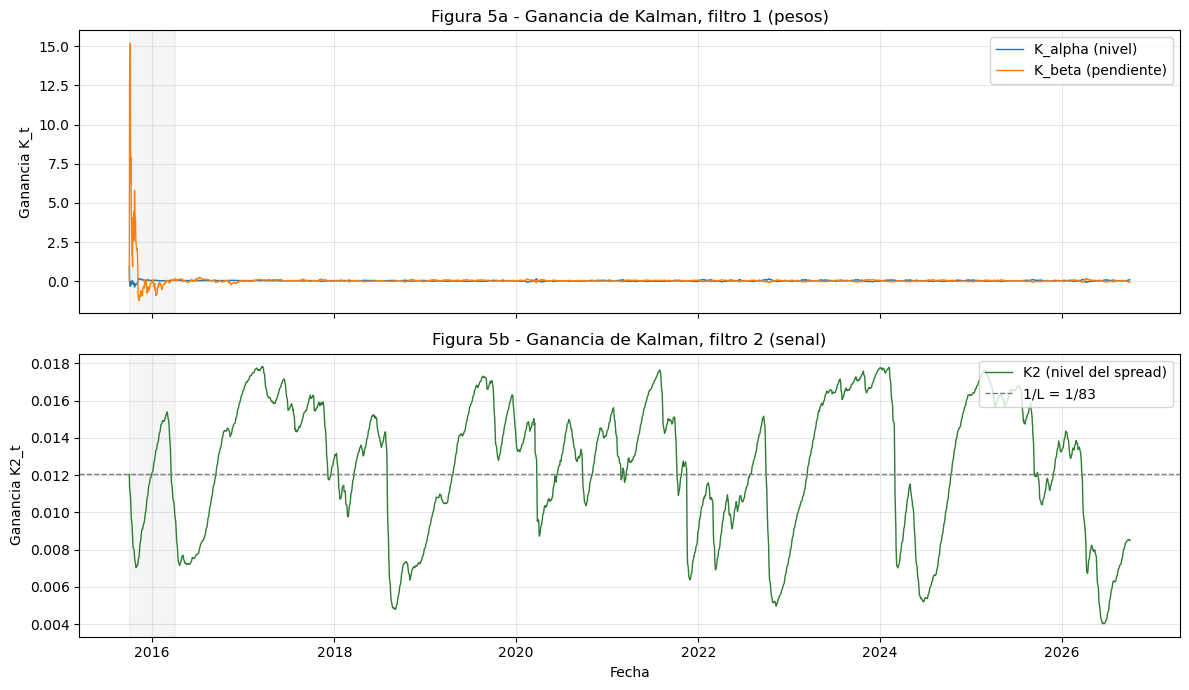

In [6]:
from kalman.filtro_pesos import centrar_x, inicializar, correr_filtro_pesos, BURN_IN
from kalman.filtro_spread import correr_filtro_spread
s  = pd.read_csv(f"{ART}/senales_kalman.csv", index_col=0, parse_dates=True)
th = json.load(open(f"{ART}/theta_optimo.json"))["kalman"]
delta, R, L2 = th["delta"], th["R"], th["L_filtro2"]
y = np.log(s["AMT"].values); x_c, _ = centrar_x(np.log(s["SBAC"].values), BURN_IN)
z0, _ = inicializar(y, x_c, BURN_IN)
f1 = correr_filtro_pesos(y, x_c, delta, z0, R); f1.index = s.index
s_init = y[:BURN_IN] - z0[1] * x_c[:BURN_IN]
f2, _ = correr_filtro_spread(s["s"].values, s_init, L2); f2.index = s.index
burn = s["en_burn_in"].astype(str).str.strip().str.lower().isin(["true", "1"]); nb_ = ~burn.values
print(f"check beta (f1): {np.abs(f1['beta_post'].values - s['beta'].values).max():.2e}  |  "
      f"check z (f2): {np.abs(f2['z'].values[nb_] - s['z'].values[nb_]).max():.2e}")
b0 = s.index[0]; b1 = s.index[burn].max() if burn.any() else None
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax1.plot(f1.index, f1["K_alpha"], lw=1, color="#1f77b4", label="K_alpha (nivel)")
ax1.plot(f1.index, f1["K_beta"],  lw=1, color="#ff7f0e", label="K_beta (pendiente)")
ax1.set_title("Figura 5a - Ganancia de Kalman, filtro 1 (pesos)")
ax1.set_ylabel("Ganancia K_t"); ax1.legend(loc="upper right"); ax1.grid(alpha=0.3)
ax2.plot(f2.index, f2["K2"], lw=1, color="#2e7d32", label="K2 (nivel del spread)")
ax2.axhline(1.0/L2, ls="--", color="gray", lw=1, label=f"1/L = 1/{L2}")
ax2.set_title("Figura 5b - Ganancia de Kalman, filtro 2 (senal)")
ax2.set_xlabel("Fecha"); ax2.set_ylabel("Ganancia K2_t"); ax2.legend(loc="upper right"); ax2.grid(alpha=0.3)
for ax in (ax1, ax2):
    if b1 is not None: ax.axvspan(b0, b1, color="gray", alpha=0.08)
plt.tight_layout(); plt.show()

### Figura 6 — z-score con umbrales
El z-score del spread con los umbrales de entrada, salida y stop; es la señal que dispara y cierra las operaciones.

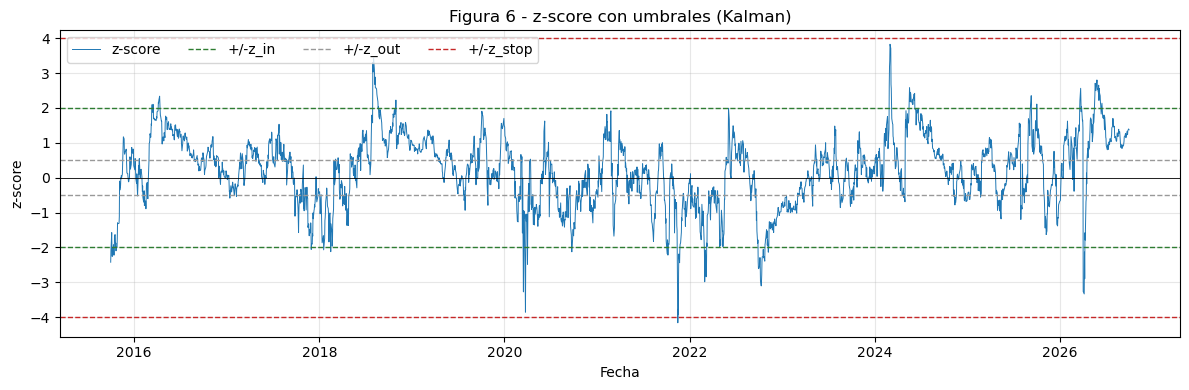

In [7]:
s = pd.read_csv(f"{ART}/senales_kalman.csv", index_col=0, parse_dates=True)
th = json.load(open(f"{ART}/theta_optimo.json"))["kalman"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.index, s["z"], lw=0.7, color="#1f77b4", label="z-score")
for val, lab, col in [(th["z_in"], "z_in", "#2e7d32"), (th["z_out"], "z_out", "#999999"), (th["z_stop"], "z_stop", "#c62828")]:
    ax.axhline(val, ls="--", lw=1, color=col, label="+/-"+lab); ax.axhline(-val, ls="--", lw=1, color=col)
ax.axhline(0, color="k", lw=0.6)
ax.set_title("Figura 6 - z-score con umbrales (Kalman)")
ax.set_xlabel("Fecha"); ax.set_ylabel("z-score"); ax.legend(loc="upper left", ncol=4); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Figura 7 — Curvas de capital (train/test/val)
Capital en las tres muestras; cada una arranca en 1,000,000 (walk-forward), así que hay un reinicio en las fronteras (líneas punteadas).

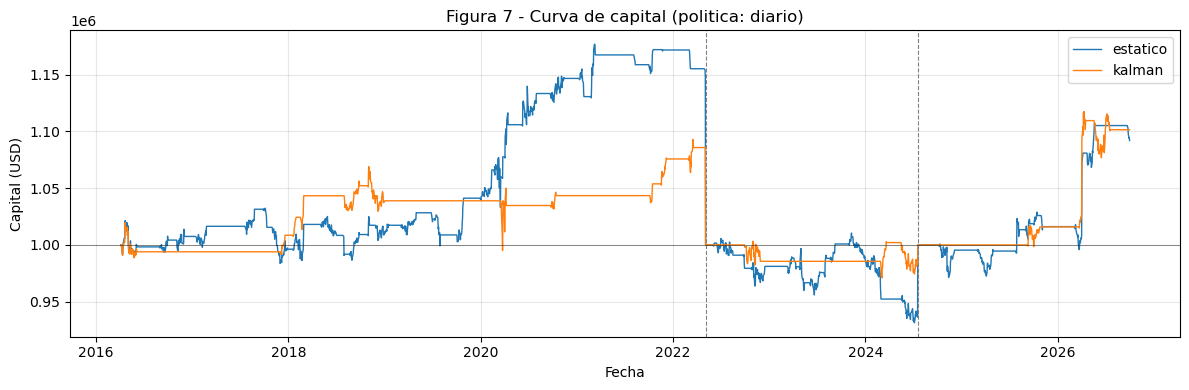

In [8]:
cfg = json.load(open(f"{ART}/bt_config.json")); pol = cfg.get("politica_oficial", "diario")
dia = pd.read_csv(f"{ART}/bt_diario.csv", parse_dates=["fecha"]); sub = dia[dia["politica"] == pol]
fig, ax = plt.subplots(figsize=(12, 4))
for metodo, g in sub.groupby("metodo"):
    g = g.sort_values("fecha"); ax.plot(g["fecha"], g["capital"], lw=1, label=metodo)
for m in ["test", "val"]:
    f0 = sub[sub["muestra"] == m]["fecha"].min()
    if pd.notna(f0): ax.axvline(f0, color="gray", ls="--", lw=0.8)
ax.axhline(1_000_000, color="k", lw=0.6, alpha=0.5)
ax.set_title(f"Figura 7 - Curva de capital (politica: {pol})")
ax.set_xlabel("Fecha"); ax.set_ylabel("Capital (USD)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Figura 8 — Distribución de retornos por operación
Histograma de los retornos por operación con una normal ajustada; muestra la forma y las colas de los resultados.

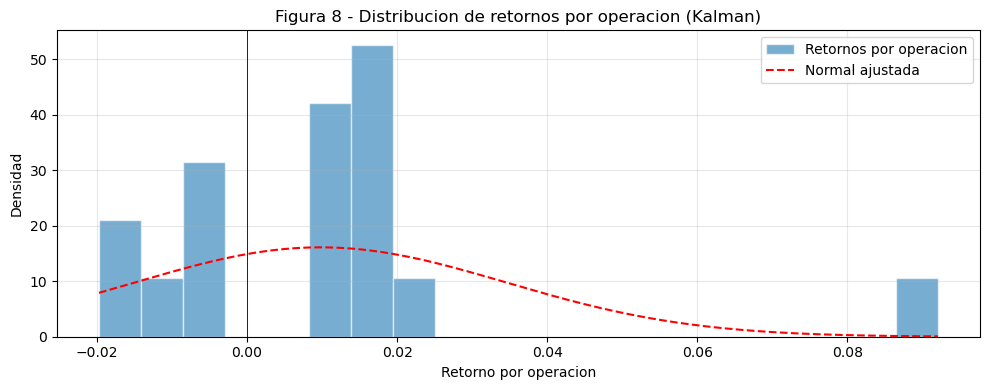

In [9]:
ops = pd.read_csv(f"{ART}/bt_operaciones.csv")
r = ops[(ops["politica"] == pol) & (ops["metodo"] == "kalman")]["retorno"].dropna()
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(r, bins=20, density=True, alpha=0.6, color="#1f77b4", edgecolor="white", label="Retornos por operacion")
if r.std() > 0:
    x = np.linspace(r.min(), r.max(), 200); ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r--", label="Normal ajustada")
ax.axvline(0, color="k", lw=0.6)
ax.set_title("Figura 8 - Distribucion de retornos por operacion (Kalman)")
ax.set_xlabel("Retorno por operacion"); ax.set_ylabel("Densidad"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Extra — Atribución de costos
Descompone el P&L bruto en neto, comisiones y préstamo; muestra cuánto de la ganancia se comen los costos.

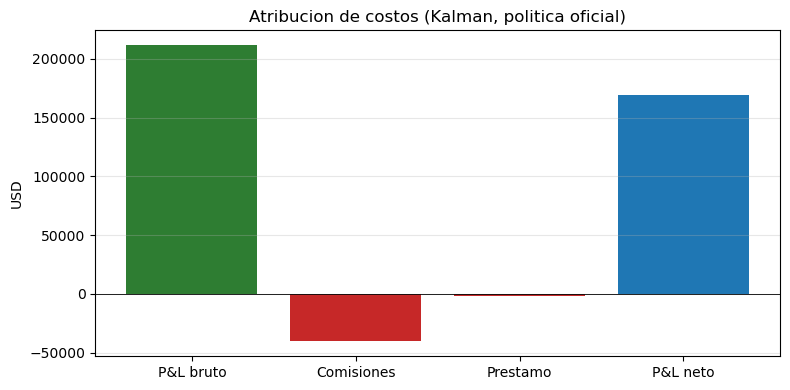

In [10]:
g = dia[(dia["politica"] == pol) & (dia["metodo"] == "kalman")]
bruto, com, pre = g["pnl_bruto"].sum(), g["comision"].sum(), g["prestamo"].sum(); neto = bruto - com - pre
vals = {"P&L bruto": bruto, "Comisiones": -com, "Prestamo": -pre, "P&L neto": neto}
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(vals.keys()), list(vals.values()), color=["#2e7d32", "#c62828", "#c62828", "#1f77b4"])
ax.axhline(0, color="k", lw=0.6); ax.set_title("Atribucion de costos (Kalman, politica oficial)")
ax.set_ylabel("USD"); ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

### Extra — Sharpe móvil de 252 días
Sharpe de los últimos 252 días a lo largo del tiempo; muestra si el desempeño ajustado por riesgo es estable.

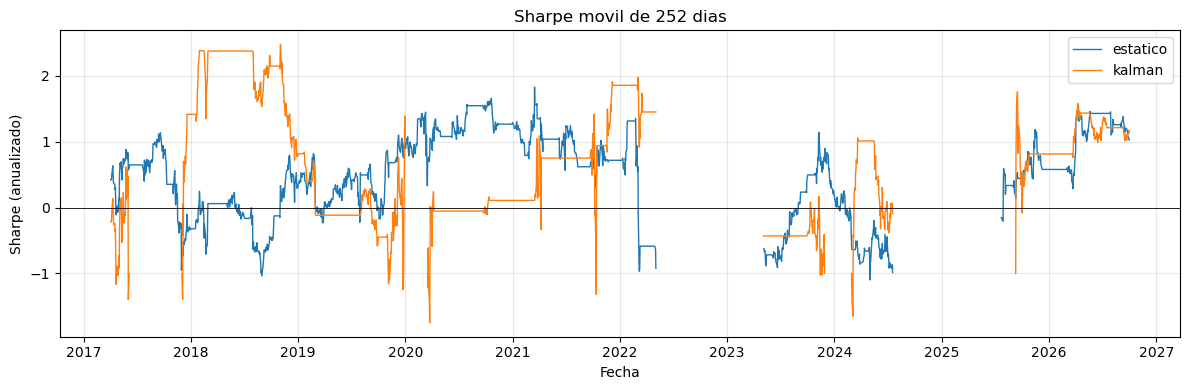

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
for metodo, g in dia[dia["politica"] == pol].groupby("metodo"):
    g = g.sort_values("fecha").copy(); g["ret"] = g.groupby("muestra")["capital"].pct_change()
    g = g.set_index("fecha"); rs = g["ret"].rolling(252).mean() / g["ret"].rolling(252).std() * np.sqrt(252)
    ax.plot(rs.index, rs, lw=1, label=metodo)
ax.axhline(0, color="k", lw=0.6); ax.set_title("Sharpe movil de 252 dias")
ax.set_xlabel("Fecha"); ax.set_ylabel("Sharpe (anualizado)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()